# Experiments on a model

The package makes inputs for sequence models and reads their outputs back,
without depending on any deep-learning library. Sequences become numpy
arrays in the layout PyTorch and most models use, and arrays or PyTorch
tensors can be passed back as they are. This guide covers:

- sequences as one-hot arrays, and motifs as convolution filters;
- how changes to a sequence alter its motif sites;
- in silico experiments, such as inserting sites or changing every base;
- references for computing contribution scores;
- inputs and targets for training a model.

We use the HS2 enhancer of the β-globin locus from the
[motifs and deep learning](deep-learning.ipynb) guide. We don't have a model
here, so the code of the experiments is shown without being run. In it,
`model` stands for a function that takes one-hot sequences and returns one
prediction for each.

In [1]:
import json
import pathlib
import urllib.request

import numpy as np
import polars as pl
import universalmotif as um

CACHE = pathlib.Path.home() / ".cache" / "universalmotif-docs"
jaspar_url = "https://jaspar.elixir.no/download/data/2024/CORE/JASPAR2024_CORE_vertebrates_non-redundant_pfms_meme.txt"
jaspar_path = CACHE / jaspar_url.rsplit("/", 1)[-1]
if not jaspar_path.exists():
    CACHE.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(jaspar_url, jaspar_path)
jaspar = um.read_meme(jaspar_path)

chrom, start, end = "chr11", 5_280_325, 5_281_325
url = f"https://api.genome.ucsc.edu/getData/sequence?genome=hg38;chrom={chrom};start={start};end={end}"
with urllib.request.urlopen(url) as response:
    seq = json.load(response)["dna"].upper()

## Sequences and filters

[`one_hot()`][universalmotif.one_hot] gives sequences as an array of shape
(sequences, letters, length), the layout of PyTorch's `Conv1d`.
[`from_one_hot()`][universalmotif.from_one_hot] turns such an array back into
strings. Letters other than A, C, G and T, such as N, become columns of zeros:

In [2]:
x = um.one_hot(seq)
print(x.shape, x.dtype)
um.from_one_hot(x[:, :, :20])

(1, 4, 1000) float32


['TGCCTTCCTCTTCCATATCC']

The first layer of most sequence models is a convolution, which slides
filters along the sequence much as a scan slides a position weight matrix.
[`to_filters()`][universalmotif.to_filters] gives motifs as weights of shape
(filters, letters, width). With `rc=True`, each motif's reverse complement
follows it as a second filter. Here is the JASPAR motif of NF-E2:

In [3]:
nfe2 = um.normalize([m for m in jaspar if m.altname == "NFE2"][0])
filters = um.to_filters(nfe2, rc=True)
print(filters.shape)

(2, 4, 10)


A convolution without a bias sums the product of a filter and the sequence
over every window. numpy can do this directly, and the best windows are the
sites a scan finds:

In [4]:
windows = np.lib.stride_tricks.sliding_window_view(x, filters.shape[2], axis=-1)
conv = np.einsum("fcw,ncpw->nfp", filters, windows)[0]
print(conv.argmax(axis=1), conv.max(axis=1).round(3))
um.scan_sequences(nfe2, seq, pvalue=1e-4).select("start", "end", "strand", "score", "pvalue")

[426 425] [18.374 15.73 ]


start,end,strand,score,pvalue
i64,i64,str,f64,f64
425,435,"""-""",15.726,0.000005
426,436,"""+""",18.368,9.5367e-7
435,445,"""-""",4.735,0.000095
436,446,"""+""",7.473,0.000038


The filters can start a model's first layer from known motifs:

```python
import torch

conv = torch.nn.Conv1d(4, filters.shape[0], filters.shape[2], bias=False)
with torch.no_grad():
    conv.weight.copy_(torch.from_numpy(filters))
```

[`from_filters()`][universalmotif.from_filters] goes the other way. It turns
first-layer weights into motifs, which can then be compared with known motifs
or drawn like any other:

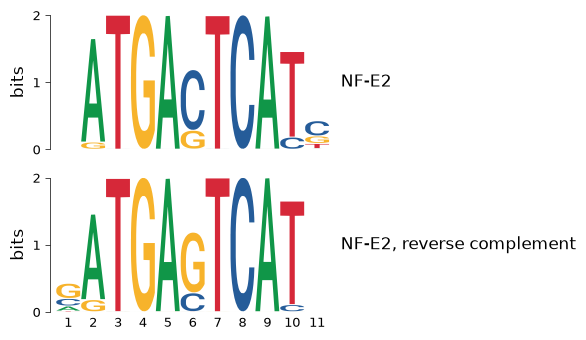

In [5]:
back = um.from_filters(filters, names=["NF-E2", "NF-E2, reverse complement"])
fig = um.view_motifs(back, rc=False, names_pos="right", figsize=(6, 3.5))

## How changes alter motif sites

Without a model we cannot predict what changing a base would do. We can ask
how each change would alter the motif sites, though.
[`variant_motif_effects()`][universalmotif.variant_motif_effects] scores every
possible substitution against the motifs, or a table of variants. It keeps
the changes to sites that pass the cutoff before or after.
[`plot_variant_effects()`][universalmotif.plot_variant_effects] draws the
largest change at each position, with the hits beneath. Here are three
erythroid factors over the core of HS2:

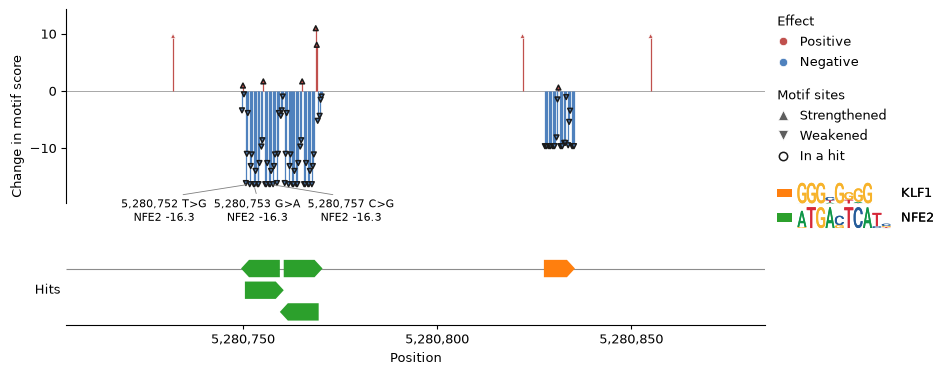

In [6]:
known = [m.replace(name=m.altname) for m in jaspar if m.altname in ("NFE2", "GATA1", "KLF1")]
a, b = 380, 560
changes = um.variant_motif_effects(None, seq[a:b], known, start=start + a, pvalue=1e-4)
strongest = changes.sort(pl.col("delta").abs(), descending=True).unique(
    "variant", keep="first", maintain_order=True
)
fig = um.plot_variant_effects(
    strongest.select("position", "ref", "alt", pl.col("delta").alias("effect")),
    sequence=seq[a:b], motifs=known, start=start + a, pvalue=1e-4,
    ylabel="Change in motif score", labels=3,
)

Nearly every substitution within the tandem NF-E2 sites weakens them. With a
model, the same plot can show the model's predicted effect of each variant
instead, such as those from
[`mutagenesis_effects()`][universalmotif.mutagenesis_effects] below. The
[variant analysis](variants.ipynb) guide scores real variants this way.

## Experiments on the input

The code from here on is not run. A common way to question a model is to
change its input and watch the prediction. These functions make the changed
sequences and take and return one-hot arrays as well as strings.

| Experiment | Functions |
| --- | --- |
| Insert a site into background sequences | [`insert_sites()`][universalmotif.insert_sites], [`plot_marginalization()`][universalmotif.plot_marginalization] |
| Place two sites at a range of spacings | [`site_spacings()`][universalmotif.site_spacings], [`plot_spacing()`][universalmotif.plot_spacing] |
| Shuffle or delete a stretch of each sequence | [`shuffle_region()`][universalmotif.shuffle_region], [`delete_region()`][universalmotif.delete_region] |
| Change every base of a sequence | [`mutagenesis()`][universalmotif.mutagenesis], [`mutagenesis_effects()`][universalmotif.mutagenesis_effects] |
| Change every pair of bases | [`pair_mutagenesis()`][universalmotif.pair_mutagenesis], [`interaction_effects()`][universalmotif.interaction_effects], [`plot_interactions()`][universalmotif.plot_interactions] |

To measure the effect of a motif on its own,
[`insert_sites()`][universalmotif.insert_sites] writes the same site into the
middle of every background sequence.
[`plot_marginalization()`][universalmotif.plot_marginalization] then draws
the predictions before and after, with the mean change. Several insertions
can be compared at once:

```python
x = um.one_hot(peak_seqs)
bkg = um.shuffle_sequences(x, seed=1)  # dinucleotide shuffles of some peaks
before = model(bkg)
fig = um.plot_marginalization(before, {
    "NF-E2": model(um.insert_sites(bkg, "TGCTGAGTCAT")),
    "half site": model(um.insert_sites(bkg, "TGAGTCA")),
    "mutated": model(um.insert_sites(bkg, "TGCTGAGTAAT")),
})
```

Factors that bind together often do so best at particular distances, such as
a whole number of turns of the helix apart.
[`site_spacings()`][universalmotif.site_spacings] writes two sites into the
background at a range of spacings.
[`plot_spacing()`][universalmotif.plot_spacing] draws the mean change in
prediction at each spacing. With `helix=True`, it marks every 10.5 bases from
the strongest:

```python
pairs = um.site_spacings(bkg, "AGATAAG", "TGCTGAGTCAT", spacings=range(41))
fig = um.plot_spacing({d: model(seqs) for d, seqs in pairs.items()}, baseline=before, helix=True)
```

Each spacing's sequences take as much memory as the background. It is best
to predict them one spacing at a time, as here, rather than in one batch.

To measure what a stretch adds in its own context,
[`shuffle_region()`][universalmotif.shuffle_region] shuffles just that
stretch of each sequence many times, keeping its dinucleotides. Each
sequence's prediction is then compared with the mean over its shuffles:

```python
ablated = um.shuffle_region(x, 485, 515, n=20, seed=1)  # (sequences, 20, 4, length)
shuffled = model(ablated.reshape(-1, *x.shape[1:])).reshape(len(x), 20).mean(axis=1)
fig = um.plot_marginalization(model(x), {"middle shuffled": shuffled})
```

[`mutagenesis()`][universalmotif.mutagenesis] makes every single-base change
of one sequence. [`mutagenesis_effects()`][universalmotif.mutagenesis_effects]
turns the model's predictions for them into an array that
`view_attributions(..., kind="heatmap")` can draw.

## Computing contribution scores

DeepLIFT and DeepSHAP measure each input against references. These are
usually shuffles of the input that keep its dinucleotides.
[`shuffled_references()`][universalmotif.shuffled_references] makes them
from one-hot sequences, keeping any Ns in place. With Captum's
`DeepLiftShap`, where `torch_model` is the PyTorch model behind `model`:

```python
import torch
from captum.attr import DeepLiftShap

x = torch.from_numpy(um.one_hot(peak_seqs))
refs = um.shuffled_references(x, n=20)  # a tensor, as x is one
explainer = DeepLiftShap(torch_model)
hypothetical = torch.cat([explainer.attribute(x[i:i + 1], baselines=refs[i]) for i in range(len(x))])
projected = hypothetical * x
```

The same references give decoy scores for calling seqlets. The model's scores
for shuffled sequences make a better null than the scores themselves
shuffled. [`call_seqlets()`][universalmotif.call_seqlets] and
[`contribution_motifs()`][universalmotif.contribution_motifs] take them as
`decoys`.

## Training data

Models of accessibility such as chromBPNet learn from peaks and from
background regions matched to them on GC content. That way GC content alone
does not predict accessibility. Given the peaks and the genome,
[`match_bkg()`][universalmotif.match_bkg] draws such regions. With
`return_ranges=True` it returns them as ranges, and measures the candidate
windows as it reads them, so a whole genome takes little memory.

Here the peaks are widened to the model's input of 2,114 bases. Windows with
any N are left out, and five negatives are drawn per peak, as a pool to
sample from in each epoch:

```python
genome = um.Genome("hg38.fa")
peaks = um.resize_ranges(um.read_bed("peaks.narrowPeak"), 2114, anchor="summit", genome=genome)
pool = um.match_bkg(None, genome=genome, target_ranges=peaks, exclude=peaks, n_per_target=5,
                    max_n_fraction=0, chromosomes=train_chroms, seed=1, return_ranges=True)
```

Calling it once per fold, each with that fold's `chromosomes`, keeps each
fold's negatives on its own chromosomes.

[`one_hot_batches()`][universalmotif.one_hot_batches] reads the regions a
batch at a time. These options matter for training:

- `bigwigs` adds the signal to predict over the middle `output_width` bases.
- `max_shift` and `reverse_complement` move and flip the regions at random,
  with the targets following their sequences.
- `seed` makes each pass reproducible.
- `strand_pairs` swaps the tracks of the two strands for regions that are
  reverse complemented.

Each epoch can then take a fresh sample of negatives, a fresh order and fresh
shifts, all from the epoch's number, so a run can be repeated exactly. Here
`train_step` stands for one step of training on a batch:

```python
cols = ["chrom", "start", "end"]
for epoch in range(n_epochs):
    negatives = pool.sample(n=peaks.height, seed=epoch)
    regions = (pl.concat([peaks.select(cols), negatives.select(cols)])
               .sample(fraction=1.0, shuffle=True, seed=epoch))
    batches = um.one_hot_batches(genome, regions, batch_size=64, bigwigs=["atac.bw"],
                                 output_width=1000, max_shift=500, reverse_complement=True,
                                 seed=epoch)
    for x, y in batches:  # (64, 4, 2114) sequences and (64, 1, 1000) targets
        loss = train_step(torch.from_numpy(x), torch.from_numpy(y))
```

Regions to validate on are read the same way, without `max_shift` and
`reverse_complement`. `one_hot_batches()` reads the genome on several threads
with `nthreads`, which is usually fast enough without worker processes. A
[`Genome`][universalmotif.Genome] can also be pickled, so batches can be read
in the workers of a PyTorch `DataLoader`. Each worker then needs its own
share of the regions and its own `seed`.